# Tuần 3: Phân vùng vùng lỗi bằng U-Net trên MVTec AD bottle

**Mục tiêu:** huấn luyện U-Net để tạo mask vùng lỗi chi tiết trên MVTec AD category `bottle`.

Vì NEU-DET không có mask pixel-level, MVTec AD được dùng cho segmentation. Split ở notebook này là **custom supervised experimental split**, không phải MVTec benchmark chính thức.

**Đầu ra Tuần 3**
- `split_manifest.csv`: danh sách train/validation/test.
- `metrics_unet.csv`: lịch sử Dice, IoU, Precision, Recall.
- `test_metrics_unet.csv`: chỉ số trên tập test.
- `checkpoints/unet_bottle_best.pt`.
- `ket_qua_phan_vung_tieng_viet.png`: ảnh gốc, mask thật, mask dự đoán và vùng lỗi dự đoán.


In [1]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import os
import sys
import random
import subprocess

SEED = 42
random.seed(SEED)

CWD = Path.cwd().resolve()
IS_KAGGLE = Path("/kaggle").exists()
KAGGLE_WORKING = Path("/kaggle/working")
KAGGLE_INPUT = Path("/kaggle/input")

def looks_like_project(path: Path) -> bool:
    return (path / "notebooks").is_dir() and (path / "datasets").is_dir()

def safe_extract_project_zip():
    if not IS_KAGGLE or not KAGGLE_INPUT.is_dir():
        return None
    target = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if looks_like_project(target):
        return target
    for zip_path in KAGGLE_INPUT.glob("**/*.zip"):
        try:
            with ZipFile(zip_path) as archive:
                names = [name.replace("\\", "/") for name in archive.namelist()]
                has_neu = any("NEU-DET/train/images/" in name for name in names)
                has_notebooks = any("/notebooks/" in name or name.startswith("notebooks/") for name in names)
                if not (has_neu and has_notebooks):
                    continue
                target.mkdir(parents=True, exist_ok=True)
                marker = target / f".extracted_{zip_path.stem}"
                if not marker.exists():
                    archive.extractall(target)
                    marker.touch()
                if looks_like_project(target):
                    return target
                nested = [p for p in target.iterdir() if p.is_dir() and looks_like_project(p)]
                if nested:
                    return nested[0]
        except (BadZipFile, OSError):
            continue
    return None

def find_project_root() -> Path:
    extracted = safe_extract_project_zip()
    candidates = []
    if extracted is not None:
        candidates.append(extracted)
    candidates += [CWD, *CWD.parents]
    kaggle_project = KAGGLE_WORKING / "Industrial_Defect_VQA"
    if kaggle_project.exists():
        candidates.insert(0, kaggle_project)
    checked = set()
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue
        if str(candidate) in checked:
            continue
        checked.add(str(candidate))
        if looks_like_project(candidate):
            return candidate
    return CWD

def find_mvtec_root(category: str = "bottle"):
    checked = []
    project_root = find_project_root()
    direct = [
        project_root / "data" / "mvtec_ad",
        project_root / "data" / "MVTec_AD",
    ]
    for candidate in direct:
        checked.append(candidate)
        if (candidate / category / "test").is_dir() and (candidate / category / "ground_truth").is_dir():
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.glob("**/" + category):
            checked.append(candidate)
            if (candidate / "test").is_dir() and (candidate / "ground_truth").is_dir():
                return candidate.parent.resolve(), checked
    return None, checked

def get_write_root(project_root: Path) -> Path:
    root = (KAGGLE_WORKING / "Industrial_Defect_VQA_runtime") if IS_KAGGLE else project_root
    root.mkdir(parents=True, exist_ok=True)
    return root

def gpu_status():
    try:
        import torch
        cuda_ok = bool(torch.cuda.is_available())
        gpu_name = torch.cuda.get_device_name(0) if cuda_ok else "Không có GPU"
    except Exception:
        cuda_ok, gpu_name = False, "Không kiểm tra được GPU"
    print("CWD:", CWD)
    print("Kaggle runtime:", IS_KAGGLE)
    print("CUDA available:", cuda_ok)
    print("GPU name:", gpu_name)
    return cuda_ok

PROJECT_ROOT = find_project_root()
WRITE_ROOT = get_write_root(PROJECT_ROOT)
print("PROJECT_ROOT:", PROJECT_ROOT)
print("WRITE_ROOT:", WRITE_ROOT)


PROJECT_ROOT: /kaggle/working
WRITE_ROOT: /kaggle/working/Industrial_Defect_VQA_runtime


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
import albumentations as A
from albumentations.pytorch import ToTensorV2
import json

plt.rcParams["font.family"] = "DejaVu Sans"

CATEGORY = "bottle"
IMAGE_SIZE = 256
RUN_TRAIN = True
QUICK_MODE = False
EPOCHS = 80
BATCH_SIZE = 8
LEARNING_RATE = 3e-4
PATIENCE = 15

CUDA_OK = gpu_status()
TRAIN_GPU_OK = CUDA_OK
MVTEC_ROOT, MVTEC_CHECKED_PATHS = find_mvtec_root(CATEGORY)
HAS_MVTEC = MVTEC_ROOT is not None
CATEGORY_ROOT = MVTEC_ROOT / CATEGORY if HAS_MVTEC else None

OUTPUT_DIR = WRITE_ROOT / "outputs" / "week03_segmentation"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
VISUAL_DIR = OUTPUT_DIR / "minh_hoa"
for folder in [OUTPUT_DIR, CHECKPOINT_DIR, VISUAL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if HAS_MVTEC:
    print("Đã tìm thấy MVTec AD:", MVTEC_ROOT)
else:
    print("Chưa tìm thấy MVTec AD bottle.")

SEED = 42


CWD: /kaggle/working
Kaggle runtime: True
CUDA available: True
GPU name: Tesla T4
Đã tìm thấy MVTec AD: /kaggle/input/datasets/ipythonx/mvtec-ad


## 1. Tạo custom supervised experimental split


In [3]:
def collect_mvtec_samples(category_root: Path):
    samples = []
    for folder_name in [("train", "good"), ("test", "good")]:
        folder = category_root / folder_name[0] / folder_name[1]
        if folder.is_dir():
            for image_path in sorted(folder.glob("*")):
                if image_path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}:
                    samples.append({
                        "image_path": str(image_path),
                        "mask_path": "",
                        "co_loi": 0,
                        "loai_loi": "good",
                    })
    for defect_dir in sorted((category_root / "test").iterdir()):
        if not defect_dir.is_dir() or defect_dir.name == "good":
            continue
        mask_dir = category_root / "ground_truth" / defect_dir.name
        for image_path in sorted(defect_dir.glob("*")):
            if image_path.suffix.lower() not in {".png", ".jpg", ".jpeg", ".bmp"}:
                continue
            mask_path = mask_dir / f"{image_path.stem}_mask.png"
            if mask_path.exists():
                samples.append({
                    "image_path": str(image_path),
                    "mask_path": str(mask_path),
                    "co_loi": 1,
                    "loai_loi": defect_dir.name,
                })
    df = pd.DataFrame(samples)
    if not df.empty:
        df['image_path_norm'] = df['image_path'].str.replace('\\', '/')
        qg_mask = df['image_path_norm'].str.endswith('test/broken_large/000.png') | df['image_path_norm'].str.endswith('test/good/000.png')
        quality_gate_df = df[qg_mask].copy()
        if not quality_gate_df.empty:
            quality_gate_df.to_csv(OUTPUT_DIR / "quality_gate_manifest.csv", index=False)
        df = df[~qg_mask].copy()
        df = df.drop(columns=['image_path_norm'])
    return df

if HAS_MVTEC:
    samples_df = collect_mvtec_samples(CATEGORY_ROOT)
    if len(samples_df) >= 30 and samples_df["co_loi"].nunique() == 2:
        train_df, remain_df = train_test_split(
            samples_df, test_size=0.30, random_state=SEED, stratify=samples_df["co_loi"]
        )
        val_df, test_df = train_test_split(
            remain_df, test_size=0.50, random_state=SEED, stratify=remain_df["co_loi"]
        )
        manifest_df = pd.concat([
            train_df.assign(tap_du_lieu="train"),
            val_df.assign(tap_du_lieu="validation"),
            test_df.assign(tap_du_lieu="test"),
        ], ignore_index=True)
        manifest_df.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
        display(manifest_df.groupby(["tap_du_lieu", "co_loi"]).size().reset_index(name="so_anh"))
    else:
        manifest_df = pd.DataFrame()
else:
    manifest_df = pd.DataFrame()


,tap_du_lieu,co_loi,so_anh
0,test,0,34
1,test,1,10
2,train,0,160
3,train,1,43
4,validation,0,34
5,validation,1,9


## 2. Dataset, U-Net và các chỉ số phân vùng


In [4]:
class MVTecSegmentationDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, is_train: bool = False, image_size: int = IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size
        self.is_train = is_train
        if self.is_train:
            self.transform = A.Compose([
                A.Resize(height=self.image_size, width=self.image_size),
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.Rotate(limit=15, p=0.5),
                A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.2),
            ])
        else:
            self.transform = A.Compose([
                A.Resize(height=self.image_size, width=self.image_size)
            ])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image_bgr = cv2.imread(row.image_path, cv2.IMREAD_COLOR)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

        if row.mask_path:
            mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE)
            mask = (mask > 0).astype(np.float32)
        else:
            mask = np.zeros(image_rgb.shape[:2], dtype=np.float32)

        transformed = self.transform(image=image_rgb, mask=mask)
        image_transformed = transformed['image']
        mask_transformed = transformed['mask']

        return (
            torch.from_numpy(image_transformed.transpose(2, 0, 1)).float() / 255.0,
            torch.from_numpy(mask_transformed[None]).float(),
            row.image_path,
            row.mask_path,
            row.co_loi
        )

class DoubleConv(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(input_channels, output_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(output_channels, output_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

class UNetSmall(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder_1 = DoubleConv(3, 32)
        self.pool_1 = nn.MaxPool2d(2)
        self.encoder_2 = DoubleConv(32, 64)
        self.pool_2 = nn.MaxPool2d(2)
        self.bridge = DoubleConv(64, 128)
        self.up_2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder_2 = DoubleConv(128, 64)
        self.up_1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder_1 = DoubleConv(64, 32)
        self.output_layer = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        encoder_1 = self.encoder_1(x)
        encoder_2 = self.encoder_2(self.pool_1(encoder_1))
        bridge = self.bridge(self.pool_2(encoder_2))
        decoder_2 = self.decoder_2(torch.cat([self.up_2(bridge), encoder_2], dim=1))
        decoder_1 = self.decoder_1(torch.cat([self.up_1(decoder_2), encoder_1], dim=1))
        return self.output_layer(decoder_1)

import torch.nn.functional as F

class FocalBCEWithDiceLoss(nn.Module):
    def __init__(self, pos_weight, alpha=0.25, gamma=2.0, eps=1e-6):
        super().__init__()
        self.pos_weight = pos_weight
        self.alpha = alpha
        self.gamma = gamma
        self.eps = eps

    def forward(self, logits, target):
        probs = torch.sigmoid(logits)
        bce_loss = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pos_weight, reduction='none')
        pt = probs * target + (1 - probs) * (1 - target)
        focal_weight = self.alpha * target + (1 - self.alpha) * (1 - target)
        focal_loss = focal_weight * (1 - pt) ** self.gamma * bce_loss
        focal_loss = focal_loss.mean()
        intersection = (probs * target).sum(dim=(1, 2, 3))
        total = probs.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
        dice_loss = 1 - ((2 * intersection + self.eps) / (total + self.eps)).mean()
        return focal_loss + dice_loss

def postprocess_probability_small(probability_small: np.ndarray, threshold: float, min_component_area_model_px: int) -> np.ndarray:
    binary = (probability_small >= threshold).astype(np.uint8)
    if min_component_area_model_px > 0 and binary.sum() > 0:
        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        cleaned = np.zeros_like(binary)
        for i in range(1, num_labels):
            if stats[i, cv2.CC_STAT_AREA] >= min_component_area_model_px:
                cleaned[labels == i] = 1
        return cleaned
    return binary

def compute_metrics_batch(logits, target, co_loi, threshold=0.5, min_component_area_model_px=0, eps=1e-6):
    probs = torch.sigmoid(logits).cpu().numpy()
    targets = target.cpu().numpy()
    co_loi_np = co_loi.cpu().numpy()
    
    batch_size = probs.shape[0]
    preds = np.zeros_like(probs)
    
    for i in range(batch_size):
        preds[i, 0] = postprocess_probability_small(probs[i, 0], threshold, min_component_area_model_px)
        
    tp = (preds * targets).sum(axis=(1, 2, 3))
    fp = (preds * (1 - targets)).sum(axis=(1, 2, 3))
    fn = ((1 - preds) * targets).sum(axis=(1, 2, 3))
    tn = ((1 - preds) * (1 - targets)).sum(axis=(1, 2, 3))
    
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    rec = (tp + eps) / (tp + fn + eps)
    
    defect_mask = (co_loi_np == 1)
    good_mask = (co_loi_np == 0)
    
    res = {}
    res["Dice_all"] = dice.mean()
    res["IoU_all"] = iou.mean()
    
    if defect_mask.sum() > 0:
        res["Dice_defect_only"] = dice[defect_mask].mean()
        res["IoU_defect_only"] = iou[defect_mask].mean()
        res["Precision_defect"] = prec[defect_mask].mean()
        res["Recall_defect"] = rec[defect_mask].mean()
        res["ty_le_anh_loi_duoc_phat_hien"] = (preds[defect_mask].sum(axis=(1,2,3)) > 0).mean()
    else:
        res["Dice_defect_only"] = 0.0
        res["IoU_defect_only"] = 0.0
        res["Precision_defect"] = 0.0
        res["Recall_defect"] = 0.0
        res["ty_le_anh_loi_duoc_phat_hien"] = 0.0
        
    if good_mask.sum() > 0:
        res["False_positive_rate_good"] = (preds[good_mask].sum(axis=(1,2,3)) > 0).mean()
        res["Specificity_good"] = 1.0 - res["False_positive_rate_good"]
        res["ty_le_anh_good_duoc_chap_nhan"] = res["Specificity_good"]
    else:
        res["False_positive_rate_good"] = 0.0
        res["Specificity_good"] = 0.0
        res["ty_le_anh_good_duoc_chap_nhan"] = 0.0
        
    return res


## 3. Huấn luyện U-Net bằng GPU Kaggle

Cập nhật: Sử dụng WeightedRandomSampler để oversample ảnh lỗi, Loss function kết hợp BCE + Dice Loss để chống lệch lớp. Early stopping và chọn threshold tự động dựa trên validation tập trung vào Dice_defect_only.

In [5]:
BEST_CHECKPOINT = CHECKPOINT_DIR / "unet_bottle_best.pt"

if RUN_TRAIN and TRAIN_GPU_OK and not manifest_df.empty:
    device = torch.device("cuda:0")
    train_df = manifest_df[manifest_df.tap_du_lieu == "train"]
    class_counts = train_df['co_loi'].value_counts().to_dict()
    weights = [1.0 / class_counts[c] for c in train_df['co_loi']]
    sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
    
    train_loader = DataLoader(
        MVTecSegmentationDataset(train_df, is_train=True),
        batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True
    )
    validation_loader = DataLoader(
        MVTecSegmentationDataset(manifest_df[manifest_df.tap_du_lieu == "validation"]),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True
    )

    model = UNetSmall().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    total_pixels = 0
    pos_pixels = 0
    for _, row in train_df.iterrows():
        total_pixels += IMAGE_SIZE * IMAGE_SIZE
        if row.co_loi == 1 and row.mask_path:
            mask = cv2.imread(row.mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is not None:
                mask = cv2.resize(mask, (IMAGE_SIZE, IMAGE_SIZE))
                pos_pixels += (mask > 0).sum()
    
    neg_pixels = total_pixels - pos_pixels
    pos_weight_val = neg_pixels / max(pos_pixels, 1)
    pos_weight_tensor = torch.tensor([pos_weight_val], dtype=torch.float32).to(device)
    print(f"Calculated pos_weight: {pos_weight_val:.4f}")
    
    criterion = FocalBCEWithDiceLoss(pos_weight=pos_weight_tensor)
    
    best_dice_defect = -1.0
    patience_counter = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []
        for images, masks, _, _, _ in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            train_losses.append(float(loss.item()))

        model.eval()
        validation_values = []
        with torch.no_grad():
            for images, masks, _, _, co_loi in validation_loader:
                logits = model(images.to(device))
                validation_values.append(compute_metrics_batch(logits.cpu(), masks, co_loi, threshold=0.5, min_component_area_model_px=0))

        epoch_row = {"epoch": epoch, "train_loss": float(np.mean(train_losses))}
        for k in validation_values[0].keys():
            epoch_row[k] = float(np.mean([item[k] for item in validation_values]))
            
        history.append(epoch_row)
        print(f"Epoch {epoch}: Train Loss {epoch_row['train_loss']:.4f}, Val Dice Defect {epoch_row['Dice_defect_only']:.4f}")

        if epoch_row["Dice_defect_only"] > best_dice_defect:
            best_dice_defect = epoch_row["Dice_defect_only"]
            torch.save({"model_state_dict": model.state_dict(), "image_size": IMAGE_SIZE}, BEST_CHECKPOINT)
            patience_counter = 0
            print(f"-> Saved new best checkpoint: {best_dice_defect:.4f}")
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print("Early stopping triggered.")
                break

    pd.DataFrame(history).to_csv(OUTPUT_DIR / "metrics_unet.csv", index=False)
    print("Đã lưu checkpoint tốt nhất:", BEST_CHECKPOINT)
else:
    print("Bỏ qua train. Cần MVTec AD bottle và Kaggle GPU.")

# Grid search post-process parameters
optimal_threshold = 0.5
optimal_min_area = 0
if BEST_CHECKPOINT.exists() and TRAIN_GPU_OK and not manifest_df.empty:
    device = torch.device("cuda:0")
    model = UNetSmall().to(device)
    model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=device)["model_state_dict"])
    model.eval()
    
    validation_loader = DataLoader(
        MVTecSegmentationDataset(manifest_df[manifest_df.tap_du_lieu == "validation"]),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True
    )
    
    thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]
    min_areas = [0, 25, 50, 100, 200, 400, 600, 800, 1000, 1500, 2000]
    
    with torch.no_grad():
        all_logits = []
        all_masks = []
        all_co_loi = []
        for images, masks, _, _, co_loi in validation_loader:
            logits = model(images.to(device)).cpu()
            all_logits.append(logits)
            all_masks.append(masks)
            all_co_loi.append(co_loi)
            
        all_logits = torch.cat(all_logits)
        all_masks = torch.cat(all_masks)
        all_co_loi = torch.cat(all_co_loi)
        
        results = []
        for t in thresholds:
            for a in min_areas:
                res = compute_metrics_batch(all_logits, all_masks, all_co_loi, threshold=t, min_component_area_model_px=a)
                
                is_valid = (
                    res["Recall_defect"] >= 0.50 and
                    res["Specificity_good"] >= 0.90 and
                    res["ty_le_anh_loi_duoc_phat_hien"] >= 0.80 and
                    res["ty_le_anh_good_duoc_chap_nhan"] >= 0.90
                )
                
                balanced = 0.0
                if res["Recall_defect"] > 0:
                    balanced = (res["Dice_defect_only"] + res["Recall_defect"] + res["Specificity_good"]) / 3.0
                    
                results.append({
                    "threshold": t,
                    "min_component_area_model_px": a,
                    "Dice_defect_only": res["Dice_defect_only"],
                    "IoU_defect_only": res["IoU_defect_only"],
                    "Recall_defect": res["Recall_defect"],
                    "Specificity_good": res["Specificity_good"],
                    "False_positive_rate_good": res["False_positive_rate_good"],
                    "ty_le_anh_loi_duoc_phat_hien": res["ty_le_anh_loi_duoc_phat_hien"],
                    "ty_le_anh_good_duoc_chap_nhan": res["ty_le_anh_good_duoc_chap_nhan"],
                    "balanced_score": balanced,
                    "is_valid_candidate": is_valid
                })
                
        df_thresh = pd.DataFrame(results)
        df_thresh.to_csv(OUTPUT_DIR / "validation_postprocess_search.csv", index=False)
        
        valid_df = df_thresh[df_thresh["is_valid_candidate"] == True]
        if valid_df.empty:
            raise RuntimeError("Không có cấu hình postprocess nào đạt yêu cầu tối thiểu của Quality Gate.")
            
        best_idx = valid_df["balanced_score"].idxmax()
        optimal_threshold = float(valid_df.loc[best_idx, "threshold"])
        optimal_min_area = int(valid_df.loc[best_idx, "min_component_area_model_px"])
        
        best_config = {
            "threshold": optimal_threshold,
            "min_component_area_model_px": optimal_min_area,
            "postprocess_space": "model_resolution",
            "reference_image_size": [IMAGE_SIZE, IMAGE_SIZE],
            "selection_status": "valid"
        }
        with open(OUTPUT_DIR / "best_postprocess_config.json", "w") as jf:
            json.dump(best_config, jf, indent=4)
            
        print(f"Optimal threshold: {optimal_threshold}, Optimal min area: {optimal_min_area}")


Calculated pos_weight: 62.2837
Epoch 1: Train Loss 1.1566, Val Dice Defect 0.0000
-> Saved new best checkpoint: 0.0000
Epoch 2: Train Loss 1.1304, Val Dice Defect 0.1966
-> Saved new best checkpoint: 0.1966
Epoch 3: Train Loss 1.1223, Val Dice Defect 0.2496
-> Saved new best checkpoint: 0.2496
Epoch 4: Train Loss 1.0977, Val Dice Defect 0.2127
Epoch 5: Train Loss 1.0958, Val Dice Defect 0.2166
Epoch 6: Train Loss 1.0908, Val Dice Defect 0.2206
Epoch 7: Train Loss 1.0768, Val Dice Defect 0.2172
Epoch 8: Train Loss 1.0706, Val Dice Defect 0.2274
Epoch 9: Train Loss 1.0748, Val Dice Defect 0.2287
Epoch 10: Train Loss 1.0803, Val Dice Defect 0.2560
-> Saved new best checkpoint: 0.2560
Epoch 11: Train Loss 1.0771, Val Dice Defect 0.2751
-> Saved new best checkpoint: 0.2751
Epoch 12: Train Loss 1.0570, Val Dice Defect 0.2614
Epoch 13: Train Loss 1.0726, Val Dice Defect 0.2753
-> Saved new best checkpoint: 0.2753
Epoch 14: Train Loss 1.0596, Val Dice Defect 0.2791
-> Saved new best checkpoint

## 4. Đánh giá tập test và tạo ảnh output tiếng Việt



--- TỔNG KẾT TEST U-NET ---


,nhom_danh_gia,so_anh,Dice_defect_only,Recall_defect,Specificity_good,False_positive_rate_good,ty_le_anh_loi_duoc_phat_hien,ty_le_anh_good_duoc_chap_nhan
0,tat_ca,44,0.674773,0.76259,0.970588,0.029412,1.0,0.970588
1,chi_anh_loi,10,0.674773,0.76259,0.000000,0.000000,1.0,0.000000
2,chi_anh_good,34,0.000000,0.00000,0.970588,0.029412,0.0,0.970588


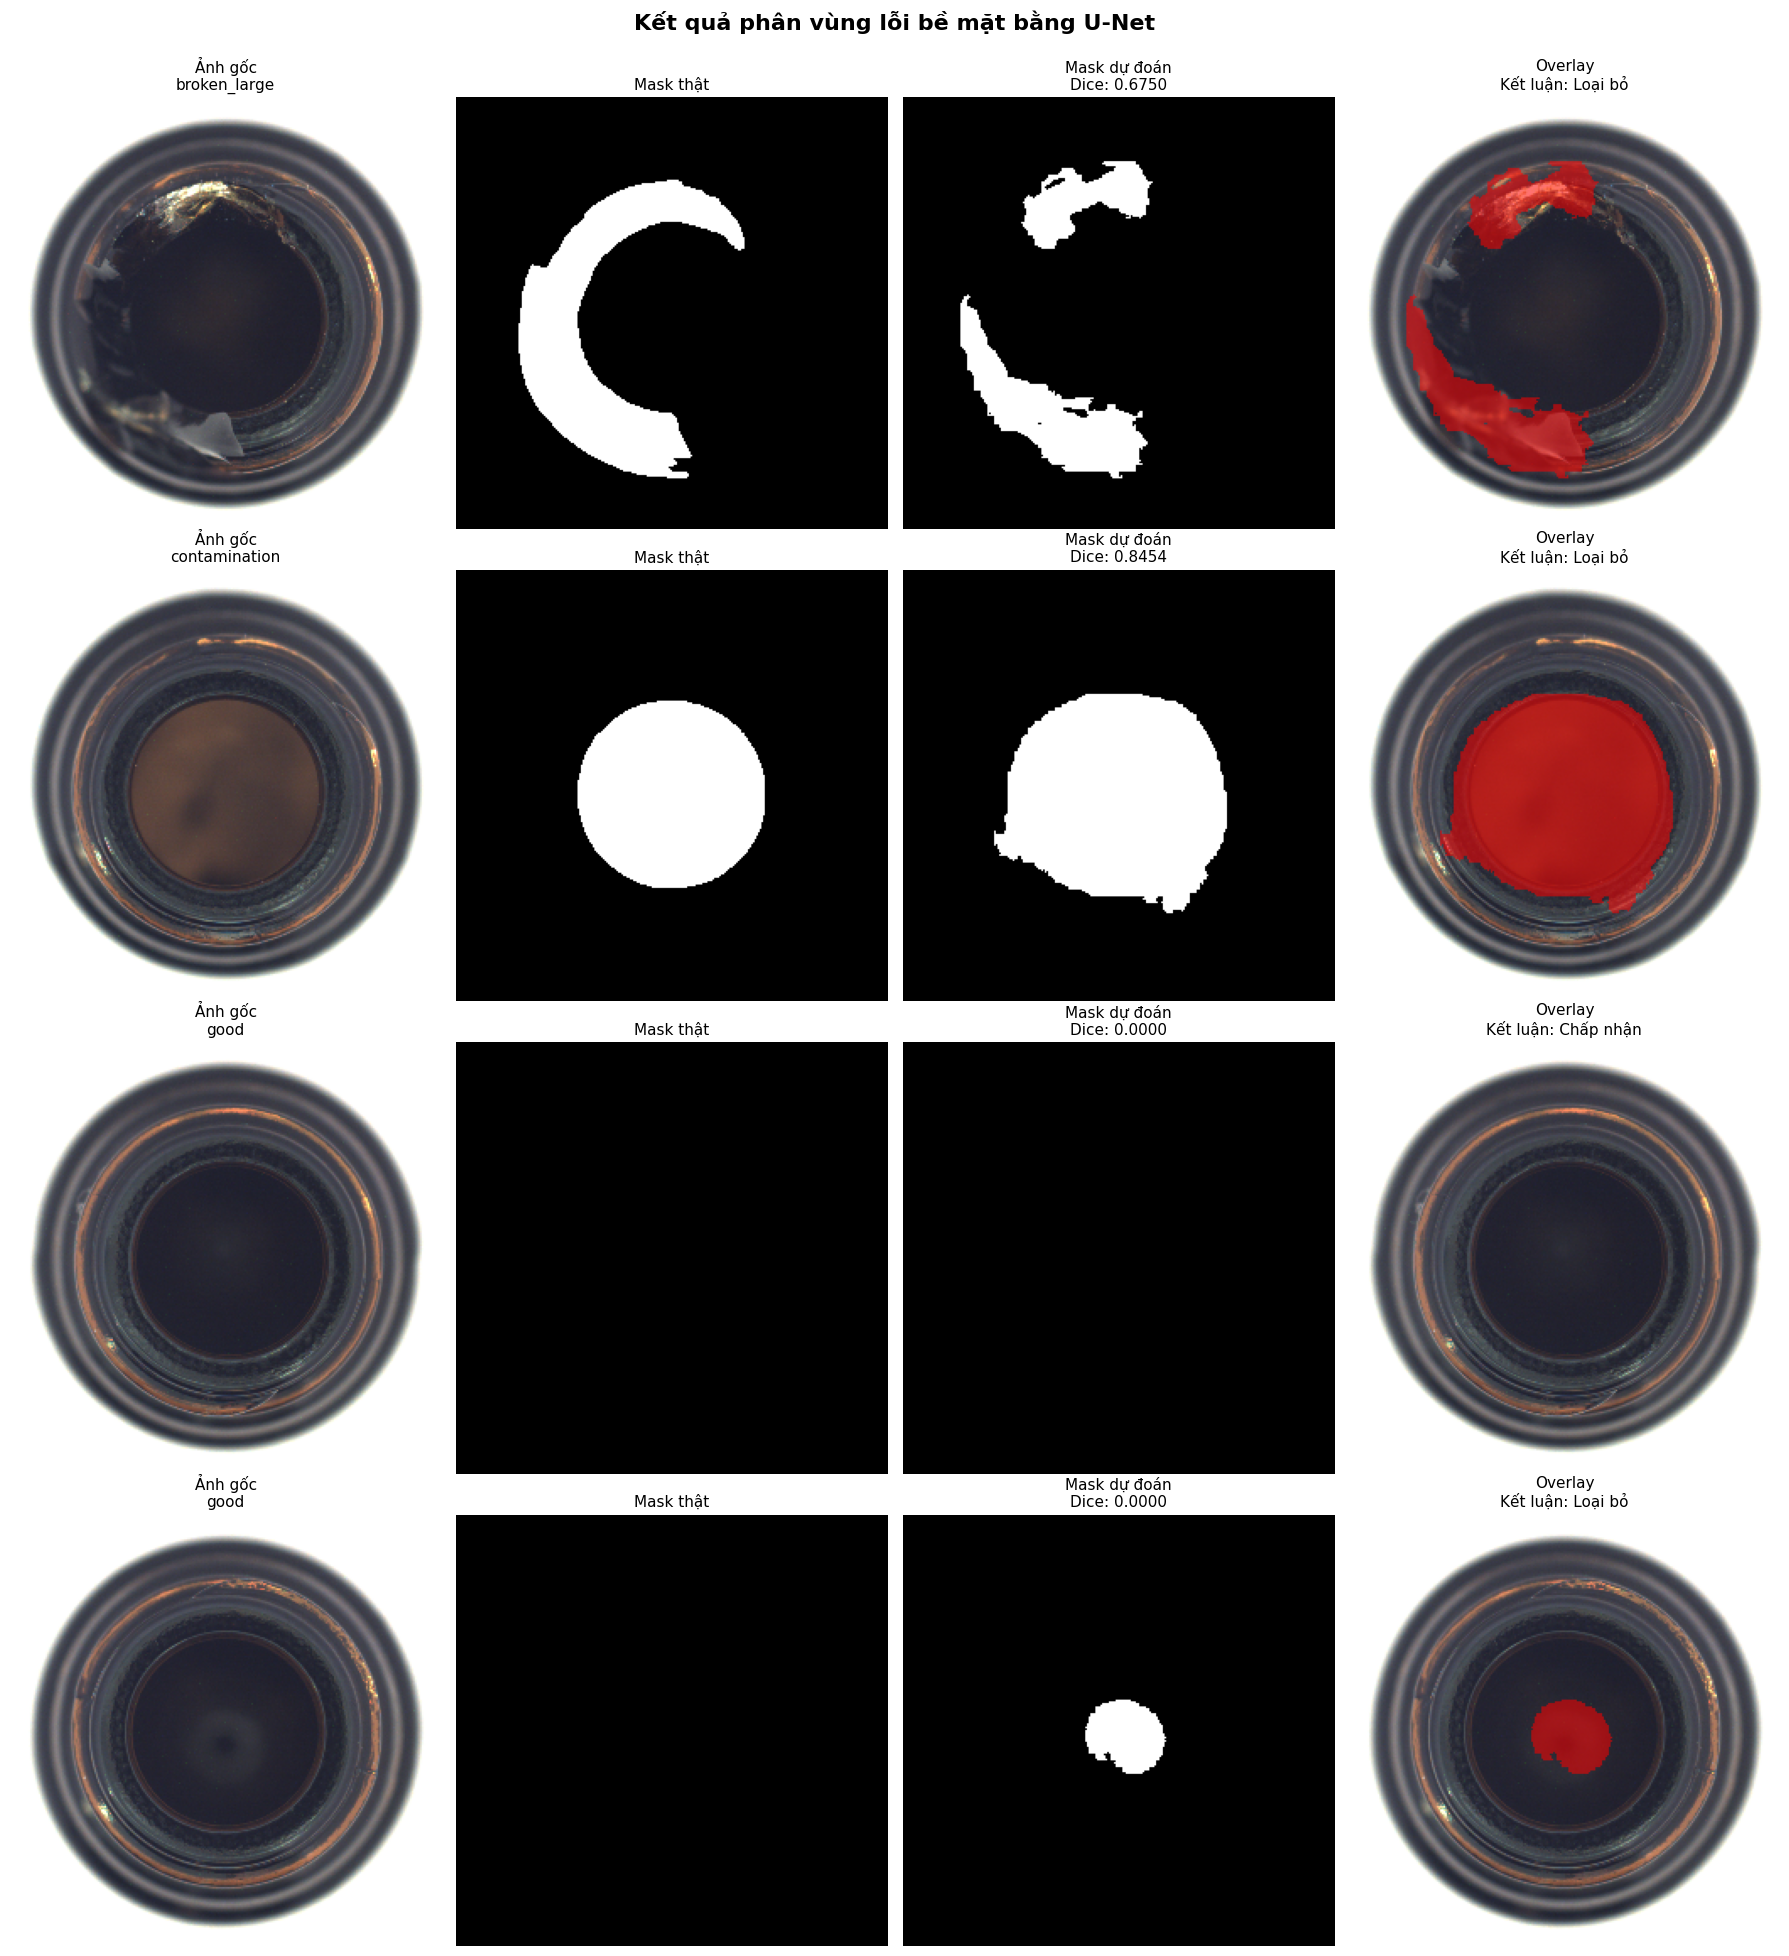


--- QUALITY GATE 1: broken_large/000.png ---

--- QUALITY GATE 2: good/000.png ---
QUALITY GATE BROKEN_LARGE: PASS (Phát hiện lỗi)
QUALITY GATE GOOD: PASS (Chấp nhận, không báo lỗi giả)

TỔNG KẾT: QUALITY GATES ĐỀU PASS. ĐỦ ĐIỀU KIỆN SANG WEEK04.


In [6]:
def save_segmentation_visualization(images_rgb, ground_truths, predictions, dices, labels, output_path: Path):
    num_imgs = len(images_rgb)
    if num_imgs == 0:
        return
    fig, axes = plt.subplots(num_imgs, 4, figsize=(18, 5 * num_imgs))
    axes = np.atleast_2d(axes)
    for i in range(num_imgs):
        image_rgb = images_rgb[i]
        ground_truth = ground_truths[i]
        prediction = predictions[i]
        dice_score = dices[i]
        label = labels[i]
        overlay = image_rgb.astype(np.float32).copy()
        defect_pixels = prediction > 0
        red_layer = np.zeros_like(overlay)
        red_layer[..., 0] = 255
        overlay[defect_pixels] = (0.45 * overlay[defect_pixels] + 0.55 * red_layer[defect_pixels])
        overlay = overlay.astype(np.uint8)
        conclusion = "Loại bỏ" if defect_pixels.sum() > 0 else "Chấp nhận"
        panels = [
            (image_rgb, f"Ảnh gốc\n{label}"),
            (ground_truth, "Mask thật"),
            (prediction, f"Mask dự đoán\nDice: {dice_score:.4f}"),
            (overlay, f"Overlay\nKết luận: {conclusion}"),
        ]
        for ax, (content, title) in zip(axes[i], panels):
            ax.imshow(content, cmap="gray" if content.ndim == 2 else None)
            ax.set_title(title, fontsize=11)
            ax.axis("off")
    fig.suptitle("Kết quả phân vùng lỗi bề mặt bằng U-Net", fontsize=16, fontweight="bold")
    plt.tight_layout()
    fig.subplots_adjust(top=0.94)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def infer_quality_gate_image(model, device, image_path, gt_path, threshold, min_area_model_px, image_size, output_path):
    if not image_path.exists():
        return None
    image_bgr = cv2.imread(str(image_path))
    if image_bgr is None:
        return None
    image_rgb_original = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    original_height, original_width = image_rgb_original.shape[:2]
    image_rgb_small = cv2.resize(image_rgb_original, (image_size, image_size), interpolation=cv2.INTER_AREA)
    image_tensor = (torch.from_numpy(image_rgb_small).permute(2, 0, 1).float() / 255.0).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(image_tensor)
        probability_small = torch.sigmoid(logits)[0, 0].cpu().numpy()
        
    prediction_small = postprocess_probability_small(probability_small, threshold, min_area_model_px)
    prediction_original = cv2.resize(prediction_small, (original_width, original_height), interpolation=cv2.INTER_NEAREST)
    probability_original = cv2.resize(probability_small, (original_width, original_height), interpolation=cv2.INTER_LINEAR)
    
    if gt_path.exists():
        gt_mask = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)
        gt_mask = (gt_mask > 0).astype(np.uint8)
    else:
        gt_mask = np.zeros((original_height, original_width), dtype=np.uint8)
        
    intersection = np.logical_and(prediction_original > 0, gt_mask > 0).sum()
    total = (prediction_original > 0).sum() + (gt_mask > 0).sum()
    dice_score = float((2 * intersection + 1e-7) / (total + 1e-7))
    
    overlay = image_rgb_original.astype(np.float32).copy()
    defect_pixels = prediction_original > 0
    red_layer = np.zeros_like(overlay)
    red_layer[..., 0] = 255
    overlay[defect_pixels] = (0.45 * overlay[defect_pixels] + 0.55 * red_layer[defect_pixels])
    overlay = overlay.astype(np.uint8)
    
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    panels = [
        (image_rgb_original, f"Ảnh: {image_path.name}"),
        (gt_mask, "Mask thật"),
        (probability_original, "Xác suất U-Net"),
        (overlay, "Overlay"),
    ]
    for ax, (content, title) in zip(axes, panels):
        ax.imshow(content, cmap="gray" if content.ndim == 2 else None)
        ax.set_title(title)
        ax.axis("off")
    fig.suptitle(
    (
        f"QUALITY GATE | threshold={threshold:.3f} | "
        f"min_area_model_px={min_area_model_px} | "
        f"Dice={dice_score:.4f} | "
        f"Pixels={int(prediction_original.sum())}"
    ),
    fontsize=13,
    fontweight="bold",
    )
    plt.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return {
        "image_path": str(image_path),
        "dice": dice_score,
        "predicted_pixels": int(prediction_original.sum()),
    }

if BEST_CHECKPOINT.exists() and TRAIN_GPU_OK and not manifest_df.empty:
    device = torch.device("cuda:0")
    model = UNetSmall().to(device)
    model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=device)["model_state_dict"])
    model.eval()
    test_manifest = manifest_df[manifest_df["tap_du_lieu"] == "test"].copy()
    
    # Get config
    config_path = OUTPUT_DIR / "best_postprocess_config.json"
    if config_path.exists():
        with open(config_path, "r") as f:
            config = json.load(f)
            optimal_threshold = config["threshold"]
            optimal_min_area = config.get("min_component_area_model_px", 0)
    
    test_loader = DataLoader(
        MVTecSegmentationDataset(test_manifest),
        batch_size=1, shuffle=False, num_workers=0,
    )
    test_rows = []
    all_test_logits = []
    all_test_masks = []
    all_test_co_loi = []
    defect_visuals = []
    good_visuals = []
    
    with torch.no_grad():
        for image, mask, image_paths, _, co_loi in test_loader:
            image_path = str(image_paths[0])
            has_defect = int(co_loi[0].item())
            logits = model(image.to(device))
            all_test_logits.append(logits.cpu())
            all_test_masks.append(mask)
            all_test_co_loi.append(co_loi)
            
            current_metrics = compute_metrics_batch(
                logits.cpu(), mask, co_loi, 
                threshold=optimal_threshold, min_component_area_model_px=optimal_min_area
            )
            
            probability_map = torch.sigmoid(logits)[0, 0].cpu().numpy()
            prediction = postprocess_probability_small(probability_map, optimal_threshold, optimal_min_area)
            predicted_pixels = int(prediction.sum())
            detected_defect = int(predicted_pixels > 0)
            
            defect_type = "good" if has_defect == 0 else test_manifest[test_manifest['image_path'] == image_path]['loai_loi'].values[0]
            
            row_data = {
                "image_path": image_path,
                "anh": Path(image_path).name,
                "loai_loi": defect_type,
                "co_loi": has_defect,
                "so_pixel_loi_du_doan": predicted_pixels,
                "co_phat_hien_loi": detected_defect,
            }
            for k, v in current_metrics.items():
                row_data[k] = float(v)
            test_rows.append(row_data)
            
            image_rgb = (image[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
            ground_truth = (mask[0, 0].cpu().numpy().astype(np.uint8))
            
            visual_item = {
                "id": image_path, "loai": defect_type, "img": image_rgb, 
                "gt": ground_truth, "pred": prediction, "dice": row_data["Dice_defect_only"] if has_defect else 0
            }
            if has_defect == 1:
                defect_visuals.append(visual_item)
            else:
                good_visuals.append(visual_item)

    test_metrics_df = pd.DataFrame(test_rows)
    test_metrics_df.to_csv(OUTPUT_DIR / "test_per_image_unet.csv", index=False)
    
    all_logits = torch.cat(all_test_logits)
    all_masks = torch.cat(all_test_masks)
    all_co_loi = torch.cat(all_test_co_loi)
    
    summary_rows = []
    for group_name, condition in [
        ("tat_ca", torch.ones_like(all_co_loi, dtype=torch.bool)),
        ("chi_anh_loi", all_co_loi == 1),
        ("chi_anh_good", all_co_loi == 0),
    ]:
        if condition.sum() == 0:
            continue
        group_logits = all_logits[condition]
        group_masks = all_masks[condition]
        group_co_loi = all_co_loi[condition]
        
        group_metrics = compute_metrics_batch(group_logits, group_masks, group_co_loi, threshold=optimal_threshold, min_component_area_model_px=optimal_min_area)
        
        row = {"nhom_danh_gia": group_name, "so_anh": len(group_logits)}
        for col in ["Dice_defect_only", "Recall_defect", "Specificity_good", "False_positive_rate_good", "ty_le_anh_loi_duoc_phat_hien", "ty_le_anh_good_duoc_chap_nhan"]:
            row[col] = float(group_metrics[col])
        summary_rows.append(row)
        
    summary_df = pd.DataFrame(summary_rows)
    summary_df.to_csv(OUTPUT_DIR / "test_summary_unet.csv", index=False)
    print("\n--- TỔNG KẾT TEST U-NET ---")
    display(summary_df)
    
    # Visualization
    selected_visuals = []
    selected_ids = set()
    # 2 defects
    for required_type in ["broken_large", "contamination", "broken_small"]:
        for v in defect_visuals:
            if v["loai"] == required_type and v["id"] not in selected_ids:
                selected_visuals.append(v)
                selected_ids.add(v["id"])
                break
        if len(selected_visuals) >= 2:
            break
    # 2 goods
    for v in good_visuals:
        if v["id"] not in selected_ids:
            selected_visuals.append(v)
            selected_ids.add(v["id"])
            if len(selected_visuals) >= 4:
                break
                
    if selected_visuals:
        save_segmentation_visualization(
            [item["img"] for item in selected_visuals],
            [item["gt"] for item in selected_visuals],
            [item["pred"] for item in selected_visuals],
            [item["dice"] for item in selected_visuals],
            [item["loai"] for item in selected_visuals],
            VISUAL_DIR / "ket_qua_phan_vung_tieng_viet.png"
        )
        
    print("\n--- QUALITY GATE 1: broken_large/000.png ---")
    broken_path = CATEGORY_ROOT / "test/broken_large/000.png"
    broken_gt = CATEGORY_ROOT / "ground_truth/broken_large/000_mask.png"
    res_broken = infer_quality_gate_image(model, device, broken_path, broken_gt, optimal_threshold, optimal_min_area, IMAGE_SIZE, VISUAL_DIR / "quality_gate_broken_large.png")
    
    print("\n--- QUALITY GATE 2: good/000.png ---")
    good_path = CATEGORY_ROOT / "test/good/000.png"
    good_gt = Path("not_exist.png")
    res_good = infer_quality_gate_image(model, device, good_path, good_gt, optimal_threshold, optimal_min_area, IMAGE_SIZE, VISUAL_DIR / "quality_gate_good.png")

    pass_broken = res_broken and res_broken["predicted_pixels"] > 0
    pass_good = res_good and res_good["predicted_pixels"] == 0
    
    if pass_broken:
        print("QUALITY GATE BROKEN_LARGE: PASS (Phát hiện lỗi)")
    else:
        print("QUALITY GATE BROKEN_LARGE: FAIL (Bỏ sót lỗi)")
        
    if pass_good:
        print("QUALITY GATE GOOD: PASS (Chấp nhận, không báo lỗi giả)")
    else:
        print("QUALITY GATE GOOD: FAIL (Báo lỗi giả trên ảnh tốt)")
        
    if pass_broken and pass_good:
        print("\nTỔNG KẾT: QUALITY GATES ĐỀU PASS. ĐỦ ĐIỀU KIỆN SANG WEEK04.")
else:
    print("Chưa có checkpoint U-Net. Cần chạy trên Kaggle GPU.")


In [7]:
from pathlib import Path
import pandas as pd
import json

OUT = Path("/kaggle/working/Industrial_Defect_VQA_runtime/outputs/week03_segmentation")
if OUT.exists() and (OUT / "test_summary_unet.csv").exists():
    summary = pd.read_csv(OUT / "test_summary_unet.csv")
    display(summary)
    
    thresholds = pd.read_csv(OUT / "validation_postprocess_search.csv")
    display(thresholds.sort_values("balanced_score", ascending=False).head(10))
    
    with open(OUT / "best_postprocess_config.json") as f:
        print("Best postprocess config:", json.load(f))


,nhom_danh_gia,so_anh,Dice_defect_only,Recall_defect,Specificity_good,False_positive_rate_good,ty_le_anh_loi_duoc_phat_hien,ty_le_anh_good_duoc_chap_nhan
0,tat_ca,44,0.674773,0.76259,0.970588,0.029412,1.0,0.970588
1,chi_anh_loi,10,0.674773,0.76259,0.000000,0.000000,1.0,0.000000
2,chi_anh_good,34,0.000000,0.00000,0.970588,0.029412,0.0,0.970588


,threshold,min_component_area_model_px,Dice_defect_only,IoU_defect_only,Recall_defect,Specificity_good,False_positive_rate_good,ty_le_anh_loi_duoc_phat_hien,ty_le_anh_good_duoc_chap_nhan,balanced_score,is_valid_candidate
31,0.50,1500,0.608335,0.453901,0.783911,0.970588,0.029412,1.000000,0.970588,0.787611,True
10,0.40,2000,0.608083,0.450710,0.865161,0.882353,0.117647,1.000000,0.882353,0.785199,False
41,0.55,1000,0.635131,0.478486,0.777889,0.941176,0.058824,1.000000,0.941176,0.784732,True
42,0.55,1500,0.576874,0.439502,0.726348,1.000000,0.000000,0.888889,1.000000,0.767740,True
20,0.45,1500,0.594402,0.439345,0.805418,0.882353,0.117647,1.000000,0.882353,0.760724,False
51,0.60,800,0.631418,0.475354,0.735557,0.911765,0.088235,1.000000,0.911765,0.759580,True
52,0.60,1000,0.580614,0.442946,0.695018,1.000000,0.000000,0.888889,1.000000,0.758544,True
53,0.60,1500,0.580614,0.442946,0.695018,1.000000,0.000000,0.888889,1.000000,0.758544,True
30,0.50,1000,0.632040,0.475092,0.814109,0.794118,0.205882,1.000000,0.794118,0.746756,False
21,0.45,2000,0.544293,0.406996,0.694307,1.000000,0.000000,0.888889,1.000000,0.746200,True


Best postprocess config: {'threshold': 0.5, 'min_component_area_model_px': 1500, 'postprocess_space': 'model_resolution', 'reference_image_size': [256, 256], 'selection_status': 'valid'}


## Hoàn thành Tuần 3

Ảnh cần trình bày là:

`outputs/week03_segmentation/minh_hoa/ket_qua_phan_vung_tieng_viet.png`

Ảnh gồm bốn phần: **Ảnh gốc, Mask thật, Mask dự đoán, Vùng lỗi dự đoán**. Đây là bằng chứng cho yêu cầu Segmentation trong đề tài.


In [8]:
print('MVTec segmentation script initialized. GPU needed for training.')


MVTec segmentation script initialized. GPU needed for training.
